In [1]:
!nvidia-smi

Sun Oct 11 23:22:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("CUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

CUDA Available: True
GPU Count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [3]:
!python -c "import socket; print(socket.gethostbyname('github.com'))"

140.82.114.4


In [4]:
!git clone https://github.com/Usman-LUMS/small-model-alignment-starter.git /kaggle/working/small-model-alignment-starter

Cloning into '/kaggle/working/small-model-alignment-starter'...
remote: Enumerating objects: 332, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 332 (delta 11), reused 11 (delta 9), pack-reused 314 (from 1)
Receiving objects: 100% (332/332), 1.07 MiB | 34.11 MiB/s, done.
Resolving deltas: 100% (186/186), done.


In [5]:
%cd /kaggle/working/small-model-alignment-starter

!pip uninstall -y -q torchao
!pip install -q -r requirements.txt
!pip install -q -e . --no-deps

/kaggle/working/small-model-alignment-starter
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 84.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 59.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Pr

In [6]:
!python -m pytest -q tests/test_public_adapter_smoke.py
!git log -1 --oneline

.......                                                                  [100%]
7 passed in 2.02s
1e04760 (HEAD -> main, origin/main, origin/HEAD) Implement SFT and DPO core functions


In [7]:
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_NAME = "Qwen/Qwen2.5-0.5B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
).to("cuda:0")

model.eval()

print("Model loaded:", MODEL_NAME)
print("Parameters:", sum(p.numel() for p in model.parameters()))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Model loaded: Qwen/Qwen2.5-0.5B
Parameters: 494032768


In [8]:
from datasets import load_dataset

SEED = 42
NUM_PROMPTS = 300

DATA_URL = (
    "https://huggingface.co/datasets/tatsu-lab/alpaca_eval/"
    "resolve/main/alpaca_eval.json"
)

dataset = load_dataset(
    "json",
    data_files=DATA_URL,
    split="train"
)

print("Total examples:", len(dataset))
print("Columns:", dataset.column_names)
print("Example:", dataset[0])

alpaca_eval.json: 0.00B [00:00, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Total examples: 805
Columns: ['dataset', 'instruction', 'output', 'generator']
Example: {'dataset': 'helpful_base', 'instruction': 'What are the names of some famous actors that started their careers on Broadway?', 'output': 'Some famous actors that started their careers on Broadway include: \n1. Hugh Jackman \n2. Meryl Streep \n3. Denzel Washington \n4. Julia Roberts \n5. Christopher Walken \n6. Anthony Rapp \n7. Audra McDonald \n8. Nathan Lane \n9. Sarah Jessica Parker \n10. Lin-Manuel Miranda', 'generator': 'text_davinci_003'}


In [9]:
import json
import random
from pathlib import Path

random.seed(SEED)

indices = random.sample(range(len(dataset)), NUM_PROMPTS)

eval_data = []

for idx in indices:
    example = dataset[idx]

    eval_data.append({
        "id": str(idx),
        "instruction": example["instruction"]
    })

output_dir = Path("outputs/baseline")
output_dir.mkdir(parents=True, exist_ok=True)

eval_path = output_dir / "alpaca_eval_300_seed42.json"

with open(eval_path, "w", encoding="utf-8") as f:
    json.dump(eval_data, f, indent=2, ensure_ascii=False)

print("Evaluation prompts:", len(eval_data))
print("Saved:", eval_path)

Evaluation prompts: 300
Saved: outputs/baseline/alpaca_eval_300_seed42.json


In [10]:
def generate_response(instruction, max_new_tokens=128):
    prompt = f"### Instruction:\n{instruction}\n\n### Response:\n"

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to("cuda:0")

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()


for example in eval_data[:3]:
    response = generate_response(example["instruction"])

    print("\nINSTRUCTION:", example["instruction"])
    print("RESPONSE:", response)
    print("-" * 70)


INSTRUCTION: Create a short, concise summary of the paper based on its abstract.

Few-shot learning (FSL) is one of the key future steps in machine learning and raises a lot of attention. In this paper, we focus on the FSL problem of dialogue understanding, which contains two closely related tasks: intent detection and slot filling. Dialogue understanding has been proven to benefit a lot from jointly learning the two sub-tasks. However, such joint learning becomes challenging in the few-shot scenarios: on the one hand, the sparsity of samples greatly magnifies the difficulty of modeling the connection between the two tasks; on the other hand, how to jointly learn multiple tasks in the few-shot setting is still less investigated. In response to this, we introduce FewJoint, the first FSL benchmark for joint dialogue understanding. FewJoint provides a new corpus with 59 different dialogue domains from real industrial API and a code platform to ease FSL experiment set-up, which are expect

In [11]:
from tqdm.auto import tqdm

baseline_results = []

for example in tqdm(eval_data, desc="Baseline generation"):
    response = generate_response(
        example["instruction"],
        max_new_tokens=128
    )

    baseline_results.append({
        "id": example["id"],
        "instruction": example["instruction"],
        "output": response,
        "generator": "qwen2.5-0.5b-base",
        "dataset": "alpaca_eval"
    })

    # Save progress every 25 examples
    if len(baseline_results) % 25 == 0:
        with open(
            output_dir / "baseline_progress.json",
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(
                baseline_results,
                f,
                indent=2,
                ensure_ascii=False
            )

print("Generated:", len(baseline_results))

Baseline generation:   0%|          | 0/300 [00:00<?, ?it/s]

Generated: 300


In [12]:
final_path = output_dir / "qwen_base_alpaca_eval_300.json"

with open(final_path, "w", encoding="utf-8") as f:
    json.dump(
        baseline_results,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Saved:", final_path)
print("Total responses:", len(baseline_results))

assert len(baseline_results) == 300
assert all("output" in item for item in baseline_results)

Saved: outputs/baseline/qwen_base_alpaca_eval_300.json
Total responses: 300


In [13]:
for example in baseline_results[:5]:
    print("=" * 80)
    print("Instruction:", example["instruction"])
    print("\nGenerated response:")
    print(example["output"])

Instruction: Create a short, concise summary of the paper based on its abstract.

Few-shot learning (FSL) is one of the key future steps in machine learning and raises a lot of attention. In this paper, we focus on the FSL problem of dialogue understanding, which contains two closely related tasks: intent detection and slot filling. Dialogue understanding has been proven to benefit a lot from jointly learning the two sub-tasks. However, such joint learning becomes challenging in the few-shot scenarios: on the one hand, the sparsity of samples greatly magnifies the difficulty of modeling the connection between the two tasks; on the other hand, how to jointly learn multiple tasks in the few-shot setting is still less investigated. In response to this, we introduce FewJoint, the first FSL benchmark for joint dialogue understanding. FewJoint provides a new corpus with 59 different dialogue domains from real industrial API and a code platform to ease FSL experiment set-up, which are expecte

In [14]:
import shutil

archive_path = shutil.make_archive(
    "/kaggle/working/pa2_baseline_outputs",
    "zip",
    root_dir=str(output_dir)
)

print("Archive created:", archive_path)

Archive created: /kaggle/working/pa2_baseline_outputs.zip


In [15]:
import os
import json
import random
import numpy as np
import torch

from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/small-model-alignment-starter")
os.chdir(PROJECT_DIR)

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B"

# First run a small training smoke test.
# Change to "full" after the smoke test succeeds.
RUN_MODE = "smoke"

TRAIN_SIZE = 64 if RUN_MODE == "smoke" else 30000
VAL_SIZE = 32 if RUN_MODE == "smoke" else 1000

MAX_LENGTH = 512
MAX_PROMPT_LENGTH = 256

BATCH_SIZE = 2
GRAD_ACCUM = 16
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.1
EPOCHS = 1

OUTPUT_DIR = PROJECT_DIR / "outputs" / f"sft_{RUN_MODE}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Mode:", RUN_MODE)
print("Training examples:", TRAIN_SIZE)
print("Validation examples:", VAL_SIZE)
print("Output:", OUTPUT_DIR)

Mode: smoke
Training examples: 64
Validation examples: 32
Output: /kaggle/working/small-model-alignment-starter/outputs/sft_smoke


In [16]:
from datasets import load_dataset

raw_train = load_dataset(
    "HuggingFaceH4/ultrachat_200k",
    split="train_sft[:50000]"
)

raw_val = load_dataset(
    "HuggingFaceH4/ultrachat_200k",
    split="test_sft[:3000]"
)

def extract_pairs(dataset, limit, seed):
    examples = []

    shuffled = dataset.shuffle(seed=seed)

    for row in shuffled:
        messages = row["messages"]

        if len(messages) < 2:
            continue

        if messages[0]["role"] != "user":
            continue

        if messages[1]["role"] != "assistant":
            continue

        prompt = messages[0]["content"].strip()
        response = messages[1]["content"].strip()

        if prompt and response:
            examples.append({
                "prompt": prompt,
                "response": response
            })

        if len(examples) == limit:
            break

    if len(examples) != limit:
        raise ValueError(
            f"Expected {limit} examples, got {len(examples)}"
        )

    return examples


train_examples = extract_pairs(raw_train, TRAIN_SIZE, SEED)
val_examples = extract_pairs(raw_val, VAL_SIZE, SEED)

print("Train:", len(train_examples))
print("Validation:", len(val_examples))
print("Example instruction:", train_examples[0]["prompt"][:200])
print("Example response:", train_examples[0]["response"][:200])

with open(OUTPUT_DIR / "data_manifest.json", "w") as f:
    json.dump({
        "source": "HuggingFaceH4/ultrachat_200k",
        "train_split": "train_sft",
        "validation_split": "test_sft",
        "seed": SEED,
        "train_examples": len(train_examples),
        "validation_examples": len(val_examples),
        "selection": "first user/assistant pair after seeded shuffle"
    }, f, indent=2)

README.md: 0.00B [00:00, ?B/s]

data/train_sft-00000-of-00003-a3ecf92756(…):   0%|          | 0.00/244M [00:00<?, ?B/s]

data/train_sft-00001-of-00003-0a1804bcb6(…):   0%|          | 0.00/244M [00:00<?, ?B/s]

data/train_sft-00002-of-00003-ee46ed25cf(…):   0%|          | 0.00/244M [00:00<?, ?B/s]

data/test_sft-00000-of-00001-f7dfac4afe5(…):   0%|          | 0.00/81.2M [00:00<?, ?B/s]

...

Generating train_sft split:   0%|          | 0/207865 [00:00<?, ? examples/s]

Generating test_sft split:   0%|          | 0/23110 [00:00<?, ? examples/s]

Generating train_gen split:   0%|          | 0/256032 [00:00<?, ? examples/s]

Generating test_gen split:   0%|          | 0/28304 [00:00<?, ? examples/s]

Train: 64
Validation: 32
Example instruction: Which museums in Bangkok have the most interactive exhibits or unique displays?
Example response: 1. Museum Siam - Known for its interactive exhibits that offer a unique look into Thai history and culture.

2. The National Museum Bangkok - Offers a vast collection of artifacts from Thailand's rich


In [17]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token


def tokenize_example(example):
    prompt = (
        "### Instruction:\n"
        + example["prompt"]
        + "\n\n### Response:\n"
    )

    prompt_ids = tokenizer.encode(
        prompt,
        add_special_tokens=False
    )[:MAX_PROMPT_LENGTH]

    response_ids = tokenizer.encode(
        example["response"],
        add_special_tokens=False
    )

    if tokenizer.eos_token_id is not None:
        response_ids.append(tokenizer.eos_token_id)

    available = MAX_LENGTH - len(prompt_ids)
    response_ids = response_ids[:available]

    input_ids = prompt_ids + response_ids

    labels = (
        [-100] * len(prompt_ids)
        + response_ids
    )

    return {
        "input_ids": input_ids,
        "labels": labels
    }


class SFTDataset(Dataset):
    def __init__(self, examples):
        self.data = [
            tokenize_example(x)
            for x in examples
        ]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


def collate_fn(batch):
    width = max(len(x["input_ids"]) for x in batch)

    input_ids = []
    labels = []
    attention_masks = []

    for example in batch:
        length = len(example["input_ids"])
        pad = width - length

        input_ids.append(
            example["input_ids"]
            + [tokenizer.pad_token_id] * pad
        )

        labels.append(
            example["labels"] + [-100] * pad
        )

        attention_masks.append(
            [1] * length + [0] * pad
        )

    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_masks, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long)
    }


train_dataset = SFTDataset(train_examples)
val_dataset = SFTDataset(val_examples)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

sample = next(iter(train_loader))

print("Input shape:", sample["input_ids"].shape)
print("Labels shape:", sample["labels"].shape)
print("Response tokens:", (sample["labels"] != -100).sum().item())

assert (sample["labels"] != -100).sum().item() > 0
assert sample["input_ids"].shape == sample["labels"].shape

Input shape: torch.Size([2, 512])
Labels shape: torch.Size([2, 512])
Response tokens: 703


In [18]:
from transformers import AutoModelForCausalLM

device = torch.device("cuda:0")

# Release previous inference model to save GPU memory.
if "model" in globals():
    del model
    import gc
    gc.collect()
    torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32
)

model.to(device)
model.train()

model.config.use_cache = False
model.gradient_checkpointing_enable()

print("Model:", MODEL_NAME)
print("Device:", next(model.parameters()).device)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Model dtype:", next(model.parameters()).dtype)

Model: Qwen/Qwen2.5-0.5B
Device: cuda:0
Trainable parameters: 494032768
Model dtype: torch.float32


In [19]:
import math
from transformers import get_cosine_schedule_with_warmup

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

steps_per_epoch = math.ceil(
    len(train_loader) / GRAD_ACCUM
)

TOTAL_STEPS = steps_per_epoch * EPOCHS
WARMUP_STEPS = max(1, int(TOTAL_STEPS * 0.03))

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=WARMUP_STEPS,
    num_training_steps=TOTAL_STEPS
)

scaler = torch.amp.GradScaler("cuda")

print("Optimizer: AdamW")
print("Total optimizer steps:", TOTAL_STEPS)
print("Warmup steps:", WARMUP_STEPS)
print("Gradient accumulation:", GRAD_ACCUM)

Optimizer: AdamW
Total optimizer steps: 2
Warmup steps: 1
Gradient accumulation: 16


In [20]:
from tqdm.auto import tqdm
import torch.nn.functional as F

training_history = []
best_val_loss = float("inf")


def compute_batch_loss(batch):
    inputs = {
        key: value.to(device)
        for key, value in batch.items()
    }

    with torch.autocast("cuda", dtype=torch.float16):
        outputs = model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

    # Shift for causal language modeling.
    logits = outputs.logits[:, :-1, :].float()
    labels = inputs["labels"][:, 1:]

    # Only response tokens contribute to loss.
    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        labels.reshape(-1),
        ignore_index=-100
    )

    return loss


@torch.no_grad()
def evaluate_sft():
    model.eval()
    losses = []

    for batch in val_loader:
        loss = compute_batch_loss(batch)
        losses.append(loss.item())

    model.train()

    return sum(losses) / len(losses)


def save_checkpoint(name):
    path = OUTPUT_DIR / name
    path.mkdir(parents=True, exist_ok=True)

    model.save_pretrained(
        path,
        safe_serialization=True
    )
    tokenizer.save_pretrained(path)

    print("Checkpoint saved:", path)


def save_metrics(record):
    with open(
        OUTPUT_DIR / "metrics.jsonl",
        "a",
        encoding="utf-8"
    ) as f:
        f.write(json.dumps(record) + "\n")


print("Training functions initialized.")

Training functions initialized.


In [21]:
import time

start_time = time.time()
global_step = 0
optimizer.zero_grad(set_to_none=True)

for epoch in range(EPOCHS):

    model.train()
    epoch_losses = []

    progress = tqdm(
        train_loader,
        desc=f"SFT Epoch {epoch + 1}/{EPOCHS}"
    )

    accumulated = 0

    for batch_idx, batch in enumerate(progress):

        loss = compute_batch_loss(batch)
        epoch_losses.append(loss.item())

        scaled_loss = loss / GRAD_ACCUM

        scaler.scale(scaled_loss).backward()
        accumulated += 1

        is_last_batch = batch_idx == len(train_loader) - 1

        if accumulated == GRAD_ACCUM or is_last_batch:

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            optimizer.zero_grad(set_to_none=True)
            accumulated = 0

            global_step += 1

            progress.set_postfix(
                loss=f"{loss.item():.4f}",
                step=global_step
            )

            eval_interval = (
                1 if RUN_MODE == "smoke" else 100
            )

            if global_step % eval_interval == 0 or global_step == TOTAL_STEPS:

                val_loss = evaluate_sft()

                record = {
                    "step": global_step,
                    "epoch": epoch + 1,
                    "train_loss": sum(epoch_losses) / len(epoch_losses),
                    "val_loss": val_loss,
                    "lr": scheduler.get_last_lr()[0]
                }

                training_history.append(record)
                save_metrics(record)

                print(
                    f"Step {global_step} | "
                    f"Train: {record['train_loss']:.4f} | "
                    f"Validation: {val_loss:.4f}"
                )

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    save_checkpoint("best")

save_checkpoint("final")

elapsed = (time.time() - start_time) / 60

print("Training complete!")
print("Minutes:", round(elapsed, 2))
print("Best validation loss:", best_val_loss)

SFT Epoch 1/1:   0%|          | 0/32 [00:00<?, ?it/s]

Step 1 | Train: 1.4511 | Validation: 1.4716
Checkpoint saved: /kaggle/working/small-model-alignment-starter/outputs/sft_smoke/best
Step 2 | Train: 1.4649 | Validation: 1.4685
Checkpoint saved: /kaggle/working/small-model-alignment-starter/outputs/sft_smoke/best
Checkpoint saved: /kaggle/working/small-model-alignment-starter/outputs/sft_smoke/final
Training complete!
Minutes: 0.41
Best validation loss: 1.4685118310153484


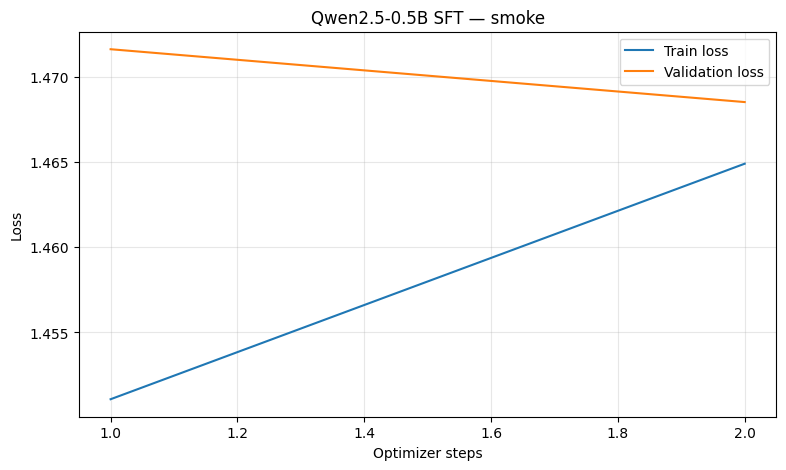

In [22]:
import matplotlib.pyplot as plt

steps = [x["step"] for x in training_history]
train_losses = [x["train_loss"] for x in training_history]
val_losses = [x["val_loss"] for x in training_history]

plt.figure(figsize=(9, 5))
plt.plot(steps, train_losses, label="Train loss")
plt.plot(steps, val_losses, label="Validation loss")

plt.xlabel("Optimizer steps")
plt.ylabel("Loss")
plt.title(f"Qwen2.5-0.5B SFT — {RUN_MODE}")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    OUTPUT_DIR / "sft_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [23]:
from pathlib import Path

best_path = OUTPUT_DIR / "best"
final_path = OUTPUT_DIR / "final"

print("Best checkpoint exists:", best_path.exists())
print("Final checkpoint exists:", final_path.exists())

assert (best_path / "config.json").exists()
assert (final_path / "config.json").exists()

print("SFT checkpoints verified.")

Best checkpoint exists: True
Final checkpoint exists: True
SFT checkpoints verified.


In [24]:
import shutil

archive = shutil.make_archive(
    f"/kaggle/working/pa2_sft_{RUN_MODE}",
    "zip",
    root_dir=str(OUTPUT_DIR)
)

print("Archive created:", archive)

Archive created: /kaggle/working/pa2_sft_smoke.zip


In [25]:
import os
import gc
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import torch

PROJECT_DIR = Path("/kaggle/working/small-model-alignment-starter")
os.chdir(PROJECT_DIR)

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
DATASET_NAME = "HuggingFaceH4/ultrachat_200k"

TRAIN_SIZE = 30000
VAL_SIZE = 1000

MAX_LENGTH = 512
MAX_PROMPT_LENGTH = 256
BATCH_SIZE = 2
GRAD_ACCUM = 16
EPOCHS = 1
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.1
EVAL_EVERY = 100

DEVICE = torch.device("cuda:0")

FULL_OUTPUT = PROJECT_DIR / "outputs" / "sft_full"
FULL_OUTPUT.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Full SFT configuration ready")
print("Training:", TRAIN_SIZE)
print("Validation:", VAL_SIZE)
print("Output:", FULL_OUTPUT)

Full SFT configuration ready
Training: 30000
Validation: 1000
Output: /kaggle/working/small-model-alignment-starter/outputs/sft_full


In [26]:
from datasets import load_dataset

raw_train_full = load_dataset(
    DATASET_NAME,
    split="train_sft"
)

raw_val_full = load_dataset(
    DATASET_NAME,
    split="test_sft"
)

def full_extract_pairs(source, size, seed):
    selected = []

    for row in source.shuffle(seed=seed):
        messages = row["messages"]

        if len(messages) < 2:
            continue

        if messages[0]["role"] != "user":
            continue

        if messages[1]["role"] != "assistant":
            continue

        prompt = messages[0]["content"].strip()
        response = messages[1]["content"].strip()

        if prompt and response:
            selected.append({
                "prompt": prompt,
                "response": response
            })

        if len(selected) == size:
            break

    if len(selected) != size:
        raise ValueError(f"Only collected {len(selected)} examples")

    return selected

full_train_examples = full_extract_pairs(
    raw_train_full, TRAIN_SIZE, SEED
)

full_val_examples = full_extract_pairs(
    raw_val_full, VAL_SIZE, SEED
)

print("Train:", len(full_train_examples))
print("Validation:", len(full_val_examples))

assert len(full_train_examples) == 30000
assert len(full_val_examples) == 1000

Train: 30000
Validation: 1000


In [27]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader

full_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if full_tokenizer.pad_token_id is None:
    full_tokenizer.pad_token = full_tokenizer.eos_token

FULL_TEMPLATE = "### Instruction:\n{instruction}\n\n### Response:\n"

def full_tokenize(example):
    prompt = FULL_TEMPLATE.format(
        instruction=example["prompt"]
    )

    prompt_ids = full_tokenizer.encode(
        prompt, add_special_tokens=False
    )[:MAX_PROMPT_LENGTH]

    response_ids = full_tokenizer.encode(
        example["response"], add_special_tokens=False
    )

    if full_tokenizer.eos_token_id is not None:
        response_ids.append(full_tokenizer.eos_token_id)

    response_ids = response_ids[:MAX_LENGTH - len(prompt_ids)]

    input_ids = prompt_ids + response_ids
    labels = [-100] * len(prompt_ids) + response_ids

    return {"input_ids": input_ids, "labels": labels}


class FullSFTDataset(Dataset):
    def __init__(self, examples):
        self.rows = [full_tokenize(x) for x in examples]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        return self.rows[index]


def full_collate(batch):
    width = max(len(x["input_ids"]) for x in batch)
    ids, labels, masks = [], [], []

    for row in batch:
        n = len(row["input_ids"])
        pad = width - n

        ids.append(
            row["input_ids"] + [full_tokenizer.pad_token_id] * pad
        )
        labels.append(row["labels"] + [-100] * pad)
        masks.append([1] * n + [0] * pad)

    return {
        "input_ids": torch.tensor(ids, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long),
        "attention_mask": torch.tensor(masks, dtype=torch.long)
    }


full_train_loader = DataLoader(
    FullSFTDataset(full_train_examples),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=full_collate
)

full_val_loader = DataLoader(
    FullSFTDataset(full_val_examples),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=full_collate
)

print("Training batches:", len(full_train_loader))
print("Validation batches:", len(full_val_loader))
print("Expected optimizer steps:",
      math.ceil(len(full_train_loader) / GRAD_ACCUM))

Training batches: 15000
Validation batches: 500
Expected optimizer steps: 938


In [28]:
from transformers import AutoModelForCausalLM

# Release models and optimizers from earlier notebook cells.
for name in [
    "model", "sft_model", "optimizer", "scheduler",
    "scaler", "full_model", "full_optimizer",
    "full_scheduler", "full_scaler"
]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

full_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32,
    low_cpu_mem_usage=True
).to(DEVICE)

full_model.config.use_cache = False
full_model.gradient_checkpointing_enable()
full_model.train()

print("Model:", MODEL_NAME)
print("Device:", next(full_model.parameters()).device)
print("Dtype:", next(full_model.parameters()).dtype)
print(
    "Trainable parameters:",
    sum(p.numel() for p in full_model.parameters() if p.requires_grad)
)

assert next(full_model.parameters()).dtype == torch.float32

Model: Qwen/Qwen2.5-0.5B
Device: cuda:0
Dtype: torch.float32
Trainable parameters: 494032768


In [29]:
from transformers import get_cosine_schedule_with_warmup

full_optimizer = torch.optim.AdamW(
    full_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

FULL_TOTAL_STEPS = math.ceil(
    len(full_train_loader) / GRAD_ACCUM
) * EPOCHS

FULL_WARMUP_STEPS = max(
    1,
    round(FULL_TOTAL_STEPS * 0.03)
)

full_scheduler = get_cosine_schedule_with_warmup(
    full_optimizer,
    num_warmup_steps=FULL_WARMUP_STEPS,
    num_training_steps=FULL_TOTAL_STEPS
)

full_scaler = torch.amp.GradScaler("cuda")

print("Total optimizer steps:", FULL_TOTAL_STEPS)
print("Warmup steps:", FULL_WARMUP_STEPS)
print("Learning rate:", LEARNING_RATE)
print("Effective batch size:", BATCH_SIZE * GRAD_ACCUM)

Total optimizer steps: 938
Warmup steps: 28
Learning rate: 2e-05
Effective batch size: 32


In [30]:
import torch.nn.functional as F

def full_compute_loss(batch):
    input_ids = batch["input_ids"].to(DEVICE)
    attention_mask = batch["attention_mask"].to(DEVICE)
    labels = batch["labels"].to(DEVICE)

    with torch.autocast("cuda", dtype=torch.float16):
        outputs = full_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False
        )

    shifted_logits = outputs.logits[:, :-1, :].float()
    shifted_labels = labels[:, 1:]

    return F.cross_entropy(
        shifted_logits.reshape(-1, shifted_logits.size(-1)),
        shifted_labels.reshape(-1),
        ignore_index=-100,
        reduction="mean"
    )


@torch.no_grad()
def full_evaluate():
    full_model.eval()

    total_loss = 0.0
    total_tokens = 0

    for batch in full_val_loader:
        loss = full_compute_loss(batch)

        tokens = (
            batch["labels"][:, 1:] != -100
        ).sum().item()

        total_loss += loss.item() * tokens
        total_tokens += tokens

    full_model.train()

    return total_loss / max(total_tokens, 1)


def full_save_checkpoint(name):
    path = FULL_OUTPUT / name
    path.mkdir(parents=True, exist_ok=True)

    full_model.save_pretrained(
        path,
        safe_serialization=True
    )

    full_tokenizer.save_pretrained(path)

    print("Saved:", path)


def full_save_metric(record):
    with open(
        FULL_OUTPUT / "metrics.jsonl",
        "a",
        encoding="utf-8"
    ) as f:
        f.write(json.dumps(record) + "\n")


print("Full SFT functions ready.")

Full SFT functions ready.


In [31]:
full_optimizer.zero_grad(set_to_none=True)
full_model.train()

test_batch = next(iter(full_train_loader))

test_loss = full_compute_loss(test_batch)

print("Initial loss:", test_loss.item())

assert torch.isfinite(test_loss).item(), "Non-finite loss"

full_scaler.scale(test_loss).backward()

has_gradients = any(
    p.grad is not None
    for p in full_model.parameters()
    if p.requires_grad
)

print("Gradients available:", has_gradients)

assert has_gradients

full_optimizer.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

print("Full SFT sanity check passed.")

Initial loss: 1.697329044342041
Gradients available: True
Full SFT sanity check passed.


In [32]:
full_optimizer.zero_grad(set_to_none=True)
full_model.train()

test_batch = next(iter(full_train_loader))

test_loss = full_compute_loss(test_batch)

print("Initial loss:", test_loss.item())

assert torch.isfinite(test_loss).item(), "Non-finite loss"

full_scaler.scale(test_loss).backward()

has_gradients = any(
    p.grad is not None
    for p in full_model.parameters()
    if p.requires_grad
)

print("Gradients available:", has_gradients)

assert has_gradients

full_optimizer.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

print("Full SFT sanity check passed.")

Initial loss: 1.2609432935714722
Gradients available: True
Full SFT sanity check passed.


In [33]:
from tqdm.auto import tqdm

full_metrics_path = FULL_OUTPUT / "metrics.jsonl"

if full_metrics_path.exists():
    raise RuntimeError(
        "Full SFT metrics already exist. "
        "Check the previous run before starting again."
    )

full_history = []
full_best_val = float("inf")
full_global_step = 0

full_start = time.time()
full_optimizer.zero_grad(set_to_none=True)

for epoch in range(EPOCHS):
    full_model.train()

    interval_loss_sum = 0.0
    interval_token_count = 0

    progress = tqdm(
        full_train_loader,
        desc=f"Full SFT Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch_idx, batch in enumerate(progress):

        # Actual accumulation window size,
        # including the smaller final window.
        window_start = (
            batch_idx // GRAD_ACCUM
        ) * GRAD_ACCUM

        window_end = min(
            window_start + GRAD_ACCUM,
            len(full_train_loader)
        )

        window_size = window_end - window_start

        loss = full_compute_loss(batch)

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite loss at batch {batch_idx}"
            )

        tokens = (
            batch["labels"][:, 1:] != -100
        ).sum().item()

        interval_loss_sum += loss.item() * tokens
        interval_token_count += tokens

        full_scaler.scale(
            loss / window_size
        ).backward()

        if batch_idx + 1 == window_end:

            full_scaler.unscale_(full_optimizer)

            torch.nn.utils.clip_grad_norm_(
                full_model.parameters(),
                max_norm=1.0
            )

            previous_scale = full_scaler.get_scale()

            full_scaler.step(full_optimizer)
            full_scaler.update()

            updated = (
                full_scaler.get_scale() >= previous_scale
            )

            if updated:
                full_scheduler.step()
                full_global_step += 1

            full_optimizer.zero_grad(set_to_none=True)

            progress.set_postfix(
                loss=f"{loss.item():.4f}",
                step=full_global_step
            )

            should_evaluate = updated and (
                full_global_step % EVAL_EVERY == 0
                or (
                    epoch == EPOCHS - 1
                    and batch_idx + 1 == len(full_train_loader)
                )
            )

            if should_evaluate:
                val_loss = full_evaluate()

                train_loss = (
                    interval_loss_sum
                    / max(interval_token_count, 1)
                )

                record = {
                    "step": full_global_step,
                    "epoch": epoch + 1,
                    "train_loss": train_loss,
                    "val_loss": val_loss,
                    "learning_rate": full_scheduler.get_last_lr()[0],
                    "elapsed_minutes": (
                        time.time() - full_start
                    ) / 60
                }

                full_history.append(record)
                full_save_metric(record)

                print(
                    f"\nStep {full_global_step}/{FULL_TOTAL_STEPS}"
                    f" | Train loss: {train_loss:.4f}"
                    f" | Validation loss: {val_loss:.4f}"
                )

                interval_loss_sum = 0.0
                interval_token_count = 0

                if val_loss < full_best_val:
                    full_best_val = val_loss
                    full_save_checkpoint("best")

full_save_checkpoint("final")

print("\nFULL SFT TRAINING COMPLETED")
print("Optimizer steps:", full_global_step)
print("Best validation loss:", full_best_val)
print(
    "Elapsed minutes:",
    round((time.time() - full_start) / 60, 2)
)

Full SFT Epoch 1/1:   0%|          | 0/15000 [00:00<?, ?it/s]


Step 100/938 | Train loss: 1.4584 | Validation loss: 1.4831
Saved: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best

Step 200/938 | Train loss: 1.4589 | Validation loss: 1.4818
Saved: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best

Step 300/938 | Train loss: 1.4536 | Validation loss: 1.4752
Saved: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best

Step 400/938 | Train loss: 1.4347 | Validation loss: 1.4659
Saved: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best

Step 500/938 | Train loss: 1.4417 | Validation loss: 1.4554
Saved: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best

Step 600/938 | Train loss: 1.4399 | Validation loss: 1.4443
Saved: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best

Step 700/938 | Train loss: 1.4080 | Validation loss: 1.4361
Saved: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best

Step 800/938 | Train loss: 1.3938 | Validation 

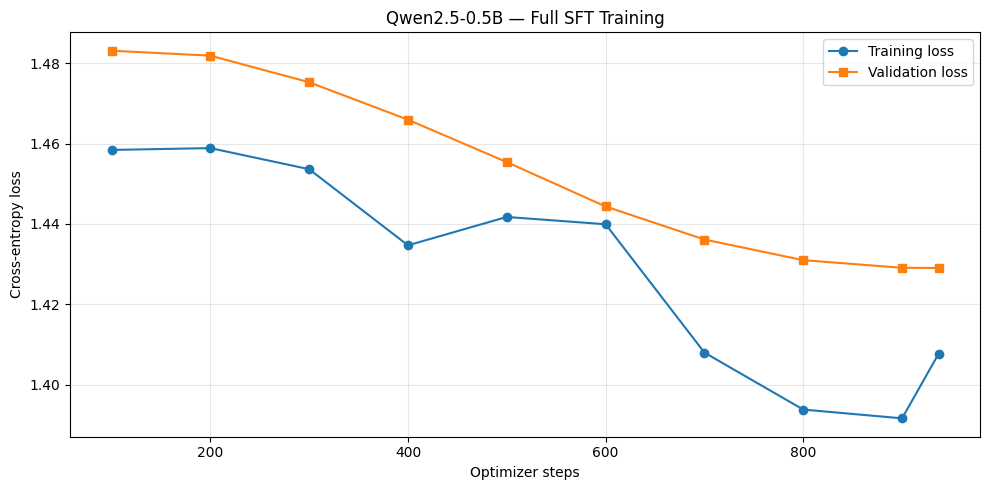

Saved plot: /kaggle/working/small-model-alignment-starter/outputs/sft_full/sft_loss.png


In [34]:
import matplotlib.pyplot as plt

assert full_history, "No training metrics recorded."

steps = [r["step"] for r in full_history]
train_losses = [r["train_loss"] for r in full_history]
val_losses = [r["val_loss"] for r in full_history]

plt.figure(figsize=(10, 5))

plt.plot(
    steps, train_losses,
    marker="o",
    label="Training loss"
)

plt.plot(
    steps, val_losses,
    marker="s",
    label="Validation loss"
)

plt.xlabel("Optimizer steps")
plt.ylabel("Cross-entropy loss")
plt.title("Qwen2.5-0.5B — Full SFT Training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plot_path = FULL_OUTPUT / "sft_loss.png"
plt.savefig(plot_path, dpi=150)
plt.show()

print("Saved plot:", plot_path)

In [35]:
full_best_path = FULL_OUTPUT / "best"
full_final_path = FULL_OUTPUT / "final"

for path in [full_best_path, full_final_path]:
    print("Checking:", path)

    assert (path / "config.json").exists()

    weights = (
        list(path.glob("*.safetensors"))
        + list(path.glob("*.bin"))
    )

    assert weights, f"No model weights found: {path}"

    print("Verified:", path.name)

print("Both full SFT checkpoints verified.")

Checking: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best
Verified: best
Checking: /kaggle/working/small-model-alignment-starter/outputs/sft_full/final
Verified: final
Both full SFT checkpoints verified.


In [36]:
from transformers import AutoModelForCausalLM

# Free training model memory.
del full_model
del full_optimizer
del full_scheduler
del full_scaler

gc.collect()
torch.cuda.empty_cache()

full_sft_inference_model = AutoModelForCausalLM.from_pretrained(
    str(full_best_path),
    torch_dtype=torch.float16
).to(DEVICE)

full_sft_inference_model.eval()

instruction = "Explain supervised fine-tuning in simple terms."

prompt = FULL_TEMPLATE.format(instruction=instruction)

inputs = full_tokenizer(
    prompt,
    return_tensors="pt"
).to(DEVICE)

with torch.inference_mode():
    generated = full_sft_inference_model.generate(
        **inputs,
        max_new_tokens=150,
        do_sample=False,
        pad_token_id=full_tokenizer.pad_token_id,
        eos_token_id=full_tokenizer.eos_token_id
    )

response_tokens = generated[0][inputs["input_ids"].shape[1]:]

response = full_tokenizer.decode(
    response_tokens,
    skip_special_tokens=True
).strip()

print("INSTRUCTION:")
print(instruction)

print("\nSFT RESPONSE:")
print(response)

INSTRUCTION:
Explain supervised fine-tuning in simple terms.

SFT RESPONSE:
Supervised fine-tuning is a process where a model is trained on a large dataset and then fine-tuned on a smaller dataset. The model is trained on the larger dataset to learn the patterns and features that are relevant to the task at hand. Then, the model is fine-tuned on the smaller dataset to improve its performance on the task. This process helps to improve the model's accuracy and reduce overfitting.


In [37]:
import shutil

# Release the inference model.
del full_sft_inference_model
gc.collect()
torch.cuda.empty_cache()

archive_path = shutil.make_archive(
    "/kaggle/working/pa2_sft_full",
    "zip",
    root_dir=str(FULL_OUTPUT)
)

print("Archive:", archive_path)
print("Archive size (GB):", round(
    Path(archive_path).stat().st_size / (1024 ** 3), 2
))

Archive: /kaggle/working/pa2_sft_full.zip
Archive size (GB): 3.42


In [38]:
from pathlib import Path
import json
import math

print("FULL SFT STATUS")
print("-" * 45)

expected_windows = math.ceil(
    len(full_train_loader) / GRAD_ACCUM
) * EPOCHS

print("Training examples:", TRAIN_SIZE)
print("Validation examples:", VAL_SIZE)
print("Completed optimizer steps:", full_global_step)
print("Planned accumulation windows:", expected_windows)
print("Skipped optimizer updates:",
      expected_windows - full_global_step)
print("Best validation loss:", full_best_val)
print("Best checkpoint:", full_best_path)
print("Final checkpoint:", full_final_path)
print("Training plot:", plot_path)
print("Archive:", archive_path)

assert full_global_step <= expected_windows
assert full_global_step > 0

assert (full_best_path / "config.json").exists()
assert (full_final_path / "config.json").exists()

assert plot_path.exists()
assert Path(archive_path).exists()

with open(FULL_OUTPUT / "training_summary.json", "w") as f:
    json.dump({
        "train_examples": TRAIN_SIZE,
        "validation_examples": VAL_SIZE,
        "planned_optimizer_steps": expected_windows,
        "successful_optimizer_steps": full_global_step,
        "skipped_optimizer_updates": expected_windows - full_global_step,
        "best_validation_loss": full_best_val,
        "status": "completed_with_skipped_update"
    }, f, indent=2)

print("\nSFT ARTIFACT VERIFICATION PASSED")

FULL SFT STATUS
---------------------------------------------
Training examples: 30000
Validation examples: 1000
Completed optimizer steps: 937
Planned accumulation windows: 938
Skipped optimizer updates: 1
Best validation loss: 1.4290417402375601
Best checkpoint: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best
Final checkpoint: /kaggle/working/small-model-alignment-starter/outputs/sft_full/final
Training plot: /kaggle/working/small-model-alignment-starter/outputs/sft_full/sft_loss.png
Archive: /kaggle/working/pa2_sft_full.zip

SFT ARTIFACT VERIFICATION PASSED


In [39]:
import os
import gc
import json
import math
import random
import time

from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

PROJECT_DIR = Path(
    "/kaggle/working/small-model-alignment-starter"
)
os.chdir(PROJECT_DIR)

SFT_CHECKPOINT = PROJECT_DIR / "outputs/sft_full/best"

assert (SFT_CHECKPOINT / "config.json").exists(), (
    "Best SFT checkpoint not found. "
    "Restore your saved SFT output before continuing."
)

DPO_ROOT = PROJECT_DIR / "outputs/dpo"
DPO_ROOT.mkdir(parents=True, exist_ok=True)

DPO_SEED = 42
DPO_TRAIN_SIZE = 15000
DPO_VAL_SIZE = 1000

DPO_MAX_LENGTH = 512
DPO_MAX_PROMPT_LENGTH = 256

DPO_BATCH_SIZE = 1
DPO_GRAD_ACCUM = 32
DPO_EPOCHS = 1

DPO_LR = 1e-6
DPO_BETA = 0.1
DPO_GRAD_CLIP = 1.0

DPO_EVAL_EVERY = 250

POLICY_DEVICE = torch.device("cuda:0")
REFERENCE_DEVICE = torch.device("cuda:1")

assert torch.cuda.device_count() >= 2, (
    "Phase 5 requires two accessible GPUs "
    "for this implementation."
)

random.seed(DPO_SEED)
np.random.seed(DPO_SEED)
torch.manual_seed(DPO_SEED)
torch.cuda.manual_seed_all(DPO_SEED)

dpo_tokenizer = AutoTokenizer.from_pretrained(
    str(SFT_CHECKPOINT)
)

if dpo_tokenizer.pad_token_id is None:
    dpo_tokenizer.pad_token = dpo_tokenizer.eos_token

DPO_PROMPT_TEMPLATE = (
    "### Instruction:\n{instruction}\n\n### Response:\n"
)

print("DPO configuration initialized.")
print("SFT checkpoint:", SFT_CHECKPOINT)
print("GPUs:", torch.cuda.device_count())
print("Beta:", DPO_BETA)
print("Training pairs:", DPO_TRAIN_SIZE)
print("Validation pairs:", DPO_VAL_SIZE)

The tokenizer you are loading from '/kaggle/working/small-model-alignment-starter/outputs/sft_full/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


DPO configuration initialized.
SFT checkpoint: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best
GPUs: 2
Beta: 0.1
Training pairs: 15000
Validation pairs: 1000


In [40]:
print("Tokenizer class:", type(dpo_tokenizer).__name__)
print("Tokenizer name:", dpo_tokenizer.name_or_path)
print("Vocabulary size:", len(dpo_tokenizer))

print("EOS token:", dpo_tokenizer.eos_token)
print("PAD token:", dpo_tokenizer.pad_token)

print("Test tokens:")
print(dpo_tokenizer.tokenize("Hello, how are you?"))

Tokenizer class: Qwen2TokenizerFast
Tokenizer name: /kaggle/working/small-model-alignment-starter/outputs/sft_full/best
Vocabulary size: 151665
EOS token: <|endoftext|>
PAD token: <|endoftext|>
Test tokens:
['Hello', ',', 'Ġhow', 'Ġare', 'Ġyou', '?']


In [41]:
def parse_hh_pair(row):
    chosen_text = row["chosen"]
    rejected_text = row["rejected"]

    separator = "\n\nAssistant:"

    if separator not in chosen_text:
        return None

    if separator not in rejected_text:
        return None

    chosen_prefix, chosen_response = chosen_text.rsplit(
        separator, 1
    )

    rejected_prefix, rejected_response = rejected_text.rsplit(
        separator, 1
    )

    if chosen_prefix != rejected_prefix:
        return None

    # Single-turn pairs only.
    # Preserve the final user instruction without
    # introducing previous assistant turns.
    if chosen_prefix.count("\n\nHuman:") != 1:
        return None

    if not chosen_prefix.startswith("\n\nHuman:"):
        return None

    prompt = chosen_prefix[len("\n\nHuman:"):].strip()
    chosen = chosen_response.strip()
    rejected = rejected_response.strip()

    if not prompt or not chosen or not rejected:
        return None

    if chosen == rejected:
        return None

    return {
        "prompt": prompt,
        "chosen": chosen,
        "rejected": rejected
    }


def parse_ultrafeedback_pair(row):
    chosen_messages = row["chosen"]
    rejected_messages = row["rejected"]

    if len(chosen_messages) != 2:
        return None

    if len(rejected_messages) != 2:
        return None

    if chosen_messages[0]["role"] != "user":
        return None

    if rejected_messages[0]["role"] != "user":
        return None

    if chosen_messages[1]["role"] != "assistant":
        return None

    if rejected_messages[1]["role"] != "assistant":
        return None

    prompt = chosen_messages[0]["content"].strip()

    if prompt != rejected_messages[0]["content"].strip():
        return None

    chosen = chosen_messages[1]["content"].strip()
    rejected = rejected_messages[1]["content"].strip()

    if not prompt or not chosen or not rejected:
        return None

    if chosen == rejected:
        return None

    return {
        "prompt": prompt,
        "chosen": chosen,
        "rejected": rejected
    }


def select_pairs(source, parser, count, seed):
    pairs = []

    for row in source.shuffle(seed=seed):
        result = parser(row)

        if result is not None:
            pairs.append(result)

        if len(pairs) == count:
            break

    if len(pairs) != count:
        raise RuntimeError(
            f"Required {count} pairs, found {len(pairs)}."
        )

    return pairs


print("Loading HH-RLHF...")

hh_train_raw = load_dataset(
    "Anthropic/hh-rlhf",
    split="train"
)

hh_val_raw = load_dataset(
    "Anthropic/hh-rlhf",
    split="test"
)

hh_train = select_pairs(
    hh_train_raw, parse_hh_pair,
    DPO_TRAIN_SIZE, DPO_SEED
)

hh_val = select_pairs(
    hh_val_raw, parse_hh_pair,
    DPO_VAL_SIZE, DPO_SEED
)

print("HH train:", len(hh_train))
print("HH validation:", len(hh_val))


print("\nLoading UltraFeedback...")

uf_train_raw = load_dataset(
    "HuggingFaceH4/ultrafeedback_binarized",
    split="train_prefs"
)

uf_val_raw = load_dataset(
    "HuggingFaceH4/ultrafeedback_binarized",
    split="test_prefs"
)

uf_train = select_pairs(
    uf_train_raw, parse_ultrafeedback_pair,
    DPO_TRAIN_SIZE, DPO_SEED
)

uf_val = select_pairs(
    uf_val_raw, parse_ultrafeedback_pair,
    DPO_VAL_SIZE, DPO_SEED
)

print("UltraFeedback train:", len(uf_train))
print("UltraFeedback validation:", len(uf_val))

assert len(hh_train) == 15000
assert len(hh_val) == 1000
assert len(uf_train) == 15000
assert len(uf_val) == 1000

print("\nBoth preference datasets prepared.")

Loading HH-RLHF...


README.md: 0.00B [00:00, ?B/s]

harmless-base/train.jsonl.gz:   0%|          | 0.00/13.2M [00:00<?, ?B/s]

helpful-base/train.jsonl.gz:   0%|          | 0.00/16.2M [00:00<?, ?B/s]

helpful-online/train.jsonl.gz:   0%|          | 0.00/20.1M [00:00<?, ?B/s]

...

Generating test_prefs split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test_sft split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating train_gen split:   0%|          | 0/61135 [00:00<?, ? examples/s]

Generating test_gen split:   0%|          | 0/1000 [00:00<?, ? examples/s]

UltraFeedback train: 15000
UltraFeedback validation: 1000

Both preference datasets prepared.


In [42]:
def encode_dpo_pair(example):
    prompt_text = DPO_PROMPT_TEMPLATE.format(
        instruction=example["prompt"]
    )

    prompt_ids = dpo_tokenizer.encode(
        prompt_text,
        add_special_tokens=False
    )[:DPO_MAX_PROMPT_LENGTH]

    def encode_response(text):
        response_ids = dpo_tokenizer.encode(
            text,
            add_special_tokens=False
        )

        if dpo_tokenizer.eos_token_id is not None:
            response_ids.append(
                dpo_tokenizer.eos_token_id
            )

        available = DPO_MAX_LENGTH - len(prompt_ids)
        response_ids = response_ids[:available]

        if not response_ids:
            raise ValueError("Empty response after truncation.")

        return {
            "input_ids": prompt_ids + response_ids,
            "labels": (
                [-100] * len(prompt_ids)
                + response_ids
            )
        }

    return {
        "chosen": encode_response(example["chosen"]),
        "rejected": encode_response(example["rejected"])
    }


class DPODataset(Dataset):
    def __init__(self, examples):
        self.rows = [
            encode_dpo_pair(example)
            for example in examples
        ]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        return self.rows[index]


def pad_dpo_sequences(rows):
    width = max(len(row["input_ids"]) for row in rows)

    input_ids = []
    labels = []
    attention_masks = []

    for row in rows:
        length = len(row["input_ids"])
        padding = width - length

        input_ids.append(
            row["input_ids"]
            + [dpo_tokenizer.pad_token_id] * padding
        )

        labels.append(
            row["labels"] + [-100] * padding
        )

        attention_masks.append(
            [1] * length + [0] * padding
        )

    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(
            attention_masks, dtype=torch.long
        ),
        "labels": torch.tensor(labels, dtype=torch.long)
    }


def dpo_collate(batch):
    return {
        "chosen": pad_dpo_sequences([
            row["chosen"] for row in batch
        ]),
        "rejected": pad_dpo_sequences([
            row["rejected"] for row in batch
        ])
    }


print("DPO dataset and batching functions ready.")

DPO dataset and batching functions ready.


In [43]:
def dpo_response_logps(model, batch, device, trainable):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    with torch.set_grad_enabled(trainable):
        with torch.autocast(
            "cuda", dtype=torch.float16
        ):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                use_cache=False
            )

        logits = outputs.logits[:, :-1, :].float()
        targets = labels[:, 1:]

        valid = targets != -100
        safe_targets = targets.masked_fill(~valid, 0)

        log_probs = F.log_softmax(logits, dim=-1)

        selected = log_probs.gather(
            -1, safe_targets.unsqueeze(-1)
        ).squeeze(-1)

        selected = selected.masked_fill(~valid, 0.0)

        return selected.sum(dim=-1)


def dpo_batch_metrics(policy, reference, batch, beta):
    policy_chosen = dpo_response_logps(
        policy, batch["chosen"], POLICY_DEVICE, True
    )

    policy_rejected = dpo_response_logps(
        policy, batch["rejected"], POLICY_DEVICE, True
    )

    reference_chosen = dpo_response_logps(
        reference, batch["chosen"],
        REFERENCE_DEVICE, False
    ).to(POLICY_DEVICE)

    reference_rejected = dpo_response_logps(
        reference, batch["rejected"],
        REFERENCE_DEVICE, False
    ).to(POLICY_DEVICE)

    chosen_reward = beta * (
        policy_chosen - reference_chosen
    )

    rejected_reward = beta * (
        policy_rejected - reference_rejected
    )

    margin = chosen_reward - rejected_reward

    loss = -F.logsigmoid(margin).mean()

    accuracy = (
        chosen_reward > rejected_reward
    ).float().mean()

    return {
        "loss": loss,
        "accuracy": accuracy,
        "margin": margin.mean()
    }


print("Manual DPO objective initialized.")

Manual DPO objective initialized.


In [44]:
def dpo_response_logps(model, batch, device, trainable):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    with torch.set_grad_enabled(trainable):
        with torch.autocast(
            "cuda", dtype=torch.float16
        ):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                use_cache=False
            )

        logits = outputs.logits[:, :-1, :].float()
        targets = labels[:, 1:]

        valid = targets != -100
        safe_targets = targets.masked_fill(~valid, 0)

        log_probs = F.log_softmax(logits, dim=-1)

        selected = log_probs.gather(
            -1, safe_targets.unsqueeze(-1)
        ).squeeze(-1)

        selected = selected.masked_fill(~valid, 0.0)

        return selected.sum(dim=-1)


def dpo_batch_metrics(policy, reference, batch, beta):
    policy_chosen = dpo_response_logps(
        policy, batch["chosen"], POLICY_DEVICE, True
    )

    policy_rejected = dpo_response_logps(
        policy, batch["rejected"], POLICY_DEVICE, True
    )

    reference_chosen = dpo_response_logps(
        reference, batch["chosen"],
        REFERENCE_DEVICE, False
    ).to(POLICY_DEVICE)

    reference_rejected = dpo_response_logps(
        reference, batch["rejected"],
        REFERENCE_DEVICE, False
    ).to(POLICY_DEVICE)

    chosen_reward = beta * (
        policy_chosen - reference_chosen
    )

    rejected_reward = beta * (
        policy_rejected - reference_rejected
    )

    margin = chosen_reward - rejected_reward

    loss = -F.logsigmoid(margin).mean()

    accuracy = (
        chosen_reward > rejected_reward
    ).float().mean()

    return {
        "loss": loss,
        "accuracy": accuracy,
        "margin": margin.mean()
    }


print("Manual DPO objective initialized.")

Manual DPO objective initialized.


In [45]:
def load_dpo_models():
    gc.collect()
    torch.cuda.empty_cache()

    policy = AutoModelForCausalLM.from_pretrained(
        str(SFT_CHECKPOINT),
        torch_dtype=torch.float32
    ).to(POLICY_DEVICE)

    reference = AutoModelForCausalLM.from_pretrained(
        str(SFT_CHECKPOINT),
        torch_dtype=torch.float16
    ).to(REFERENCE_DEVICE)

    policy.config.use_cache = False
    policy.gradient_checkpointing_enable()
    policy.train()

    reference.config.use_cache = False
    reference.eval()
    reference.requires_grad_(False)

    assert all(
        not p.requires_grad
        for p in reference.parameters()
    )

    return policy, reference


print("Model loading function ready.")

Model loading function ready.


In [46]:
@torch.no_grad()
def evaluate_dpo(policy, reference, val_loader):
    policy.eval()
    reference.eval()

    total_loss = 0.0
    total_accuracy = 0.0
    total_margin = 0.0
    total_examples = 0

    for batch in val_loader:
        metrics = dpo_batch_metrics(
            policy, reference, batch, DPO_BETA
        )

        count = batch["chosen"]["input_ids"].size(0)

        total_loss += metrics["loss"].item() * count
        total_accuracy += metrics["accuracy"].item() * count
        total_margin += metrics["margin"].item() * count
        total_examples += count

    policy.train()

    if total_examples == 0:
        raise RuntimeError("No validation examples.")

    return {
        "val_loss": total_loss / total_examples,
        "reward_accuracy": total_accuracy / total_examples,
        "reward_margin": total_margin / total_examples
    }


def save_dpo_checkpoint(policy, output_dir, name):
    path = output_dir / name
    path.mkdir(parents=True, exist_ok=True)

    policy.save_pretrained(
        path,
        safe_serialization=True
    )

    dpo_tokenizer.save_pretrained(path)

    print("Checkpoint saved:", path)


def append_dpo_metric(output_dir, record):
    with open(
        output_dir / "metrics.jsonl",
        "a",
        encoding="utf-8"
    ) as f:
        f.write(json.dumps(record) + "\n")


print("DPO validation and checkpoint functions ready.")

DPO validation and checkpoint functions ready.


In [47]:
def train_dpo_experiment(
    name,
    train_examples,
    val_examples,
    smoke=False
):
    output_dir = DPO_ROOT / (
        f"{name}_smoke" if smoke else name
    )

    output_dir.mkdir(parents=True, exist_ok=True)

    metrics_path = output_dir / "metrics.jsonl"

    if metrics_path.exists():
        raise RuntimeError(
            f"Existing metrics found in {output_dir}. "
            "Use a new run directory rather than "
            "overwriting existing results."
        )

    if smoke:
        train_examples = train_examples[:4]
        val_examples = val_examples[:4]

    train_dataset = DPODataset(train_examples)
    val_dataset = DPODataset(val_examples)

    generator = torch.Generator()
    generator.manual_seed(DPO_SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=DPO_BATCH_SIZE,
        shuffle=True,
        generator=generator,
        collate_fn=dpo_collate
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=DPO_BATCH_SIZE,
        shuffle=False,
        collate_fn=dpo_collate
    )

    print("\nStarting:", name)
    print("Training pairs:", len(train_dataset))
    print("Validation pairs:", len(val_dataset))

    # Every experiment starts from the original SFT best.
    policy, reference = load_dpo_models()

    optimizer = torch.optim.AdamW(
        policy.parameters(),
        lr=DPO_LR
    )

    scaler = torch.amp.GradScaler("cuda")

    total_windows = (
        math.ceil(len(train_loader) / DPO_GRAD_ACCUM)
        * DPO_EPOCHS
    )

    completed_steps = 0
    skipped_updates = 0
    history = []

    best_accuracy = -1.0
    best_val_loss = float("inf")

    start_time = time.time()

    optimizer.zero_grad(set_to_none=True)

    config = {
        "experiment": name,
        "smoke": smoke,
        "initial_policy": str(SFT_CHECKPOINT),
        "reference_model": str(SFT_CHECKPOINT),
        "train_pairs": len(train_dataset),
        "validation_pairs": len(val_dataset),
        "beta": DPO_BETA,
        "learning_rate": DPO_LR,
        "optimizer": "AdamW",
        "batch_size": DPO_BATCH_SIZE,
        "gradient_accumulation": DPO_GRAD_ACCUM,
        "epochs": DPO_EPOCHS,
        "max_length": DPO_MAX_LENGTH,
        "max_prompt_length": DPO_MAX_PROMPT_LENGTH,
        "seed": DPO_SEED,
        "precision": "FP32 policy, FP16 reference",
        "prompt_template": DPO_PROMPT_TEMPLATE
    }

    with open(output_dir / "config.json", "w") as f:
        json.dump(config, f, indent=2)

    for epoch in range(DPO_EPOCHS):
        policy.train()

        progress = tqdm(
            train_loader,
            desc=f"{name} Epoch {epoch + 1}"
        )

        interval_losses = []

        for batch_idx, batch in enumerate(progress):

            window_start = (
                batch_idx // DPO_GRAD_ACCUM
            ) * DPO_GRAD_ACCUM

            window_end = min(
                window_start + DPO_GRAD_ACCUM,
                len(train_loader)
            )

            window_size = window_end - window_start

            metrics = dpo_batch_metrics(
                policy, reference, batch, DPO_BETA
            )

            loss = metrics["loss"]

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    f"Non-finite DPO loss at batch {batch_idx}"
                )

            interval_losses.append(loss.item())

            scaler.scale(
                loss / window_size
            ).backward()

            if batch_idx + 1 == window_end:
                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    policy.parameters(),
                    DPO_GRAD_CLIP
                )

                old_scale = scaler.get_scale()

                scaler.step(optimizer)
                scaler.update()

                updated = (
                    scaler.get_scale() >= old_scale
                )

                if updated:
                    completed_steps += 1
                else:
                    skipped_updates += 1

                optimizer.zero_grad(set_to_none=True)

                progress.set_postfix(
                    loss=f"{loss.item():.4f}",
                    step=completed_steps
                )

                should_evaluate = (
                    smoke
                    or (batch_idx + 1 == len(train_loader))
                    or (
                        updated
                        and completed_steps % DPO_EVAL_EVERY == 0
                    )
                )

                if should_evaluate:
                    validation = evaluate_dpo(
                        policy,
                        reference,
                        val_loader
                    )

                    record = {
                        "step": completed_steps,
                        "epoch": epoch + 1,
                        "train_loss": (
                            sum(interval_losses)
                            / len(interval_losses)
                        ),
                        **validation,
                        "elapsed_minutes": (
                            time.time() - start_time
                        ) / 60
                    }

                    history.append(record)

                    append_dpo_metric(
                        output_dir, record
                    )

                    interval_losses.clear()

                    print(
                        f"\n{name} | Step {completed_steps}"
                        f" | DPO loss: {record['train_loss']:.4f}"
                        f" | Val loss: {validation['val_loss']:.4f}"
                        f" | Accuracy: {validation['reward_accuracy']:.4f}"
                        f" | Margin: {validation['reward_margin']:.4f}"
                    )

                    accuracy = validation["reward_accuracy"]
                    val_loss = validation["val_loss"]

                    improved = (
                        accuracy > best_accuracy
                        or (
                            accuracy == best_accuracy
                            and val_loss < best_val_loss
                        )
                    )

                    if improved:
                        best_accuracy = accuracy
                        best_val_loss = val_loss

                        save_dpo_checkpoint(
                            policy, output_dir, "best"
                        )

    save_dpo_checkpoint(
        policy, output_dir, "final"
    )

    summary = {
        "experiment": name,
        "smoke": smoke,
        "train_pairs": len(train_dataset),
        "validation_pairs": len(val_dataset),
        "planned_optimizer_windows": total_windows,
        "completed_optimizer_steps": completed_steps,
        "skipped_updates": skipped_updates,
        "best_reward_accuracy": best_accuracy,
        "best_validation_loss": best_val_loss,
        "elapsed_minutes": (
            time.time() - start_time
        ) / 60
    }

    with open(output_dir / "summary.json", "w") as f:
        json.dump(summary, f, indent=2)

    # Release resources before the next experiment.
    del policy
    del reference
    del optimizer
    del scaler

    gc.collect()
    torch.cuda.empty_cache()

    print("\nExperiment completed:", name)
    print(json.dumps(summary, indent=2))

    return summary

In [48]:
def dpo_response_logps(model, batch, device, trainable):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    with torch.set_grad_enabled(trainable):
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False
        )

        logits = outputs.logits[:, :-1, :].float()
        targets = labels[:, 1:]

        valid = targets != -100
        safe_targets = targets.masked_fill(~valid, 0)

        log_probs = torch.nn.functional.log_softmax(
            logits, dim=-1
        )

        selected = log_probs.gather(
            -1, safe_targets.unsqueeze(-1)
        ).squeeze(-1)

        selected = selected.masked_fill(~valid, 0.0)

        return selected.sum(dim=-1)


print("DPO FP32 computation enabled.")

DPO FP32 computation enabled.


In [49]:
scaler = torch.amp.GradScaler("cuda")

In [50]:
# Diagnose checkpoint saving failure without rerunning training

import shutil
import os
from pathlib import Path

checkpoint_dir = (
    Path("/kaggle/working/small-model-alignment-starter")
    / "outputs/dpo/hh_rlhf_smoke_fp32/best"
)

disk = shutil.disk_usage("/kaggle/working")

print("DISK STATUS")
print("Total GB:", round(disk.total / 1024**3, 2))
print("Used GB:", round(disk.used / 1024**3, 2))
print("Free GB:", round(disk.free / 1024**3, 2))

print("\nCHECKPOINT DIRECTORY")
print("Directory exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    for file in checkpoint_dir.iterdir():
        print(
            file.name,
            round(file.stat().st_size / 1024**2, 2),
            "MB"
        )

print("\nCHECKPOINT STORAGE TEST")

test_file = checkpoint_dir.parent / "write_test.txt"

try:
    test_file.write_text("checkpoint write test")
    print("File writing: SUCCESS")
    test_file.unlink()
except Exception as e:
    print("File writing: FAILED")
    print(type(e).__name__, str(e))

DISK STATUS
Total GB: 19.52
Used GB: 14.22
Free GB: 5.29

CHECKPOINT DIRECTORY
Directory exists: False

CHECKPOINT STORAGE TEST
File writing: FAILED
FileNotFoundError [Errno 2] No such file or directory: '/kaggle/working/small-model-alignment-starter/outputs/dpo/hh_rlhf_smoke_fp32/write_test.txt'


In [51]:
import os
from pathlib import Path

paths = [
    "/kaggle/working/pa2_sft_full.zip",
    "/kaggle/working/pa2_sft_smoke.zip",
    "/kaggle/working/pa2_baseline_outputs.zip",
    "/kaggle/working/small-model-alignment-starter/outputs",
]

for path in paths:
    p = Path(path)

    if not p.exists():
        continue

    if p.is_file():
        size = p.stat().st_size
    else:
        size = sum(
            f.stat().st_size
            for f in p.rglob("*")
            if f.is_file()
        )

    print(f"{size / 1024**3:.2f} GB — {path}")

3.42 GB — /kaggle/working/pa2_sft_full.zip
3.37 GB — /kaggle/working/pa2_sft_smoke.zip
0.00 GB — /kaggle/working/pa2_baseline_outputs.zip
7.42 GB — /kaggle/working/small-model-alignment-starter/outputs


In [52]:
from pathlib import Path
import shutil

root = Path("/kaggle/working")
project = root / "small-model-alignment-starter"

# Ensure the essential SFT checkpoint remains intact.
assert (project / "outputs/sft_full/best/config.json").exists()

# Delete downloaded duplicate ZIPs from Kaggle.
for filename in [
    "pa2_sft_smoke.zip",
    "pa2_sft_full.zip",
    "pa2_baseline_outputs.zip",
]:
    path = root / filename
    if path.exists():
        path.unlink()
        print("Deleted:", filename)

usage = shutil.disk_usage(root)
print("\nFree disk space:", round(usage.free / 1024**3, 2), "GB")

Deleted: pa2_sft_smoke.zip
Deleted: pa2_sft_full.zip
Deleted: pa2_baseline_outputs.zip

Free disk space: 12.08 GB


In [53]:
import shutil
import subprocess

print("Disk usage:")
subprocess.run(["df", "-h", "/kaggle/working"])

print("\nLargest files and folders:")
subprocess.run(
    ["du", "-h", "--max-depth=3",
     "/kaggle/working/small-model-alignment-starter/outputs"]
)

print("\nMemory usage:")
subprocess.run(["free", "-h"])

Disk usage:
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  7.5G   13G  39% /kaggle/working

Largest files and folders:
1.9G	/kaggle/working/small-model-alignment-starter/outputs/sft_smoke/best
1.9G	/kaggle/working/small-model-alignment-starter/outputs/sft_smoke/final
3.8G	/kaggle/working/small-model-alignment-starter/outputs/sft_smoke
544K	/kaggle/working/small-model-alignment-starter/outputs/baseline
4.0K	/kaggle/working/small-model-alignment-starter/outputs/dpo
1.9G	/kaggle/working/small-model-alignment-starter/outputs/sft_full/best
1.9G	/kaggle/working/small-model-alignment-starter/outputs/sft_full/final
3.8G	/kaggle/working/small-model-alignment-starter/outputs/sft_full
7.5G	/kaggle/working/small-model-alignment-starter/outputs

Memory usage:
               total        used        free      shared  buff/cache   available
Mem:            31Gi       5.9Gi       3.7Gi        15Mi        22Gi        25Gi
Swap:             0B          0B          0B


CompletedProcess(args=['free', '-h'], returncode=0)

In [54]:
from pathlib import Path
from IPython.display import display, FileLink
import shutil

root = Path("/kaggle/working")

zip_files = sorted(root.rglob("*.zip"))

print(f"Found {len(zip_files)} ZIP files:\n")

for file in zip_files:
    size_gb = file.stat().st_size / (1024**3)
    print(f"{file.name} — {size_gb:.2f} GB")
    display(FileLink(str(file)))

print("\nDownload all ZIP files using the links above.")

Found 0 ZIP files:


Download all ZIP files using the links above.
